# RAG evaluation for Brazilian Portuguese technical documentation

The evaluation measures three outcomes separately. The first is whether the retrieved passages contain the annotated evidence. The second is whether the answer is substantively correct. The third is whether the cited passages support the answer.

## 1. Setup and integrity

Run the notebook with the project dependencies and either the repository root or the notebook directory as the working directory. The evaluation reads the frozen corpus, saved rankings, logged answers and returned blind grades. All calculations and figures use local files.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

root = Path.cwd()
if not (root / "rag_models.toml").is_file():
    root = root.parent
sys.path.insert(0, str(root / "src"))

import evaluate
import rag
from common import read_jsonl, verify_manifest

data = root / "data"
runs = root / "runs"
figures = root / "report" / "figures"
figures.mkdir(parents=True, exist_ok=True)

manifest = json.loads((data / "MANIFEST.json").read_text(encoding="utf-8"))
verify_manifest(data, *manifest["files"])
summary = evaluate.evaluate(data_dir=data, runs_dir=runs, config_path=root / "rag_models.toml")
corpus, paired = summary["corpus"], summary["paired"]
retrieval, results = summary["retrieval"], summary["rag"]
questions = {row["qa_id"]: row for row in read_jsonl(data / "eval_set_v2.jsonl")}
chunks = {row["chunk_id"]: row for row in read_jsonl(data / "chunks_v2.jsonl")}
slots = {row["g_id"]: row for row in paired["slots"]}
primary = results["default_models"][0]
primary_log = read_jsonl(rag.paths_for(runs, primary)["runs"])
retriever_labels = {"tfidf": "TF-IDF", "dense": "Dense"}
model_names = list(results["models"])
provider_labels = {"gemini": "Gemini API", "ollama": "Ollama"}
hosted_count = sum(results["models"][name]["provider"] == "gemini" for name in model_names)
blue, teal, amber, ink = "#23486b", "#007c78", "#e2a345", "#152739"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": ink,
    "axes.labelcolor": ink,
    "xtick.color": ink,
    "ytick.color": ink,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "axes.axisbelow": True,
    "grid.color": "#dde5ec",
    "legend.frameon": False,
    "savefig.facecolor": "white",
})


def show_figure(fig, name):
    fig.savefig(figures / name, dpi=300, bbox_inches="tight", pad_inches=0.08)
    plt.show()
    plt.close(fig)


print(f"Verified {len(manifest['files'])} frozen files against MANIFEST.json.")
print(f"Evaluated {results['overall']['n']} blind grades from {len(model_names)} configured models.")

Verified 10 frozen files against MANIFEST.json.
Evaluated 70 blind grades from 7 configured models.


## 2. Corpus and traceable chunking (M1)

The source is `Madras1/rag-qa-fulltext-ptbr` (ODC-By). Selection used a seeded stream, technical-domain and length filters, a single literally unique evidence span, and a Gemini judge. Human review rejected 9 of the 36 accepted candidates before the first 25 remaining documents were frozen.

Each question maps to one document and one annotated evidence span. Every chunk covering the complete span is gold. Chunk text is a slice of the NFC-normalized document, with character offsets and a stable `chk_<doc_id>_<index>_<sha256[:8]>` ID.

In [2]:
display(Markdown(
    f"Dataset revision `{corpus['revision']}`. Windows contain up to {corpus['chunk_size_words']} words "
    f"with {corpus['chunk_overlap_words']} words of overlap."
))
word_rows = {
    "Documents": corpus["document_words"],
    "Chunks": corpus["chunk_words"],
}
display(pd.DataFrame.from_dict(word_rows, orient="index").rename(
    columns={"n": "Count", "total": "Total words", "median": "Median", "min": "Minimum", "max": "Maximum"}
))
display(pd.Series(corpus["document_types"], name="Documents").rename_axis("Document type").to_frame())

for label, ids in (("Paired questions", paired["paired"]), ("Highlighted questions", paired["highlighted"])):
    display(Markdown(f"**{label}** ({len(ids)}) — " + ", ".join(f"`{qa_id}`" for qa_id in ids)))

Dataset revision `a9546f0d67416f3f2df57007f0ae60fde0cc0fab`. Windows contain up to 300 words with 50 words of overlap.

,Count,Total words,Median,Minimum,Maximum
Documents,25,18943,691,408,1340
Chunks,83,21843,300,53,300


,Documents
Document type,
faq,3
manual,10
tutorial,12


**Paired questions** (5) — `Q021`, `Q004`, `Q001`, `Q024`, `Q009`

**Highlighted questions** (3) — `Q021`, `Q004`, `Q001`

## 3. TF-IDF and dense retrieval (M2)

Both retrievers rank all chunks for each question. TF-IDF uses lowercasing, Unicode accent handling and no stop-word list. Dense retrieval uses `gemini-embedding-001` with 3,072 dimensions and cosine similarity in float64. Evidence recall@k is the share of questions with a gold chunk in the top k. MRR averages the reciprocal rank of the first gold chunk. Document recall@1 uses the document ID of the first chunk.

The exact random baseline uses the hypergeometric probability of seeing at least one of the gold chunks in the first k draws. Its document recall@1 is the mean fraction of chunks in each question's target document. Offline reciprocal rank fusion (RRF) sums $1/(60+r)$ over the two full rankings and breaks ties by chunk ID.

In [3]:
methods = {
    "TF-IDF": retrieval["retrievers"]["tfidf"],
    "Dense": retrieval["retrievers"]["dense"],
    "Exact random": retrieval["random"],
    "Offline RRF": retrieval["rrf"],
}
retrieval_table = pd.DataFrame.from_dict({
    name: {
        **{f"Chunk recall@{k}": row["evidence_recall_at_k"][str(k)] for k in (1, 3, 5)},
        "MRR": row["mrr"],
        "Document recall@1": row["doc_recall_at_1"],
    }
    for name, row in methods.items()
}, orient="index")
display(retrieval_table.map("{:.3f}".format))

paired_counts = pd.DataFrame.from_dict(retrieval["paired_counts"], orient="index")
display(paired_counts.rename(columns={
    "both": "Both", "dense_only": "Dense only", "tfidf_only": "TF-IDF only", "neither": "Neither"
}).rename_axis("Cutoff k"))

diagnostics = {}
for name, method in retrieval["retrievers"].items():
    misses = method["evidence_misses"]
    diagnostics[retriever_labels[name]] = {
        "Target document at rank 1": method["doc_hits_at_1"],
        "Within-document misses at k=1": len(misses["1"]["target_document_present"]),
        "Cross-document misses at k=1": len(misses["1"]["target_document_absent"]),
        "Within-document misses at k=3": ", ".join(misses["3"]["target_document_present"]) or "None",
    }
display(pd.DataFrame.from_dict(diagnostics, orient="index"))
display(pd.DataFrame(methods["TF-IDF"]["wrong_doc_at_1"]))

,Chunk recall@1,Chunk recall@3,Chunk recall@5,MRR,Document recall@1
TF-IDF,0.640,1.000,1.000,0.800,0.960
Dense,0.640,0.960,1.000,0.803,1.000
Exact random,0.013,0.039,0.065,0.063,0.040
Offline RRF,0.640,0.960,1.000,0.803,1.000


,Both,Dense only,TF-IDF only,Neither
Cutoff k,,,,
1,13,3,3,6
3,24,0,1,0
5,25,0,0,0


,Target document at rank 1,Within-document misses at k=1,Cross-document misses at k=1,Within-document misses at k=3
TF-IDF,24,8,1,None
Dense,25,9,0,Q024


,qa_id,question,gold_doc_id,ranked_doc_id,ranked_chunk_id,first_gold_rank
0,Q005,Em que formatos os dados estão disponíveis?,D005,D011,chk_D011_001_a3d053f3,2


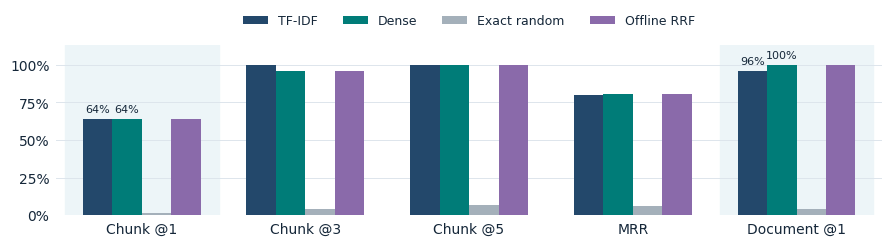

In [4]:
fig, ax = plt.subplots(figsize=(8.8, 2.35), layout="constrained")
positions = np.arange(len(retrieval_table.columns))
width = 0.18

ax.axvspan(-0.47, 0.47, color="#edf5f8", zorder=0)
ax.axvspan(3.53, 4.47, color="#edf5f8", zorder=0)
for index, (label, color) in enumerate(zip(retrieval_table.index, [blue, teal, "#a4b0ba", "#8a6aaa"])):
    bars = ax.bar(positions + (index - 1.5) * width, retrieval_table.loc[label], width, color=color, label=label)
    if label in ("TF-IDF", "Dense"):
        for position in (0, 4):
            bar = bars[position]
            ax.annotate(f"{bar.get_height():.0%}", (bar.get_x() + width / 2, bar.get_height()),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

ax.set(
    xticks=positions, xticklabels=["Chunk @1", "Chunk @3", "Chunk @5", "MRR", "Document @1"],
    yticks=[0, 0.25, 0.50, 0.75, 1], ylim=(0, 1.13), xlim=(-0.52, 4.52),
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.grid(axis="y", linewidth=0.7)
ax.tick_params(length=0, pad=5)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.04), ncol=4, fontsize=9)
show_figure(fig, "retrieval_comparison.png")

TF-IDF retrieves the right document first for 24 of 25 questions and dense does so for all 25. Both retrieve the annotated chunk first for 16. The sole cross-document top-1 miss is TF-IDF on Q005. The only top-3 evidence miss is also within the right document, on dense Q024. RRF recovers the same number of gold hits as dense at each cutoff and leaves Q024 outside the top three.

With 25 questions and small paired differences, these values describe the frozen sample. They provide no reliable estimate of the advantage on another corpus.

## 4. Controlled RAG and blind human grading (M3–M4)

The fixed Portuguese prompt supplies the top three passages in rank order and requests `answerable`, `cited` and `answer`. Every model uses temperature 0 and seed 42. Ollama also fixes the context to 8,192 tokens, caps output at 1,024 tokens and disables thinking. The default Gemini model was the only model used to develop the frozen prompt.

Member B graded each model's 10 answers with the retriever hidden, using `Correct`, `Partial` and `Wrong`. Citation support was judged separately as `Yes`, `No` or `N/A` for an empty mapped citation list. The evaluator joins the returned CSVs to the final logs by `g_id`. It recomputes gold presence, gold citation and consistency from the logged answer and retrieved chunks. Consistency checks the answerability and citation format. Citation support asks whether the cited text substantiates the response.

In [5]:
stats = results["models"][primary]["settings"]
display(Markdown(
    f"**Primary model** `{primary}`. **Prompt version** `{stats['prompt_version']}`. **Context size** K = {stats['k']}."
))
display(pd.DataFrame([
    {
        "Slot": r["g_id"],
        "Question": r["qa_id"],
        "Highlighted": "Yes" if slots[r["g_id"]]["highlighted"] else "",
        "Retriever": retriever_labels[r["retriever"]],
        "Gold rank": slots[r["g_id"]]["first_gold_rank"],
        "Gold in context": r["gold_in_context"],
        "Cited positions": r["cited_numbers"],
        "Grade": r["grade"],
        "Support": r["cited_supports"],
    }
    for r in results["answer_grades"] if r["model"] == primary
]).set_index("Slot"))


def compare_pair(left, right):
    if left == right:
        return "Identical set and order"
    return "Same set, different order" if set(left) == set(right) else "Different sets"


display(pd.DataFrame([
    {
        "Question": qa_id,
        "Top-three comparison": compare_pair(*[
            row["retrieved_chunk_ids"] for row in slots.values() if row["qa_id"] == qa_id
        ]),
    }
    for qa_id in paired["paired"]
]).set_index("Question"))

q009 = [r for r in primary_log if r["qa_id"] == "Q009"]
print(f"Q009 primary-model prompts identical: {q009[0]['prompt_text'] == q009[1]['prompt_text']}")
print(f"Q009 primary-model answer text identical: {q009[0]['answer'] == q009[1]['answer']}")

**Primary model** `gemini-3.5-flash-lite`. **Prompt version** `13c74fac6aa7`. **Context size** K = 3.

,Question,Highlighted,Retriever,Gold rank,Gold in context,Cited positions,Grade,Support
Slot,,,,,,,,
G01,Q021,Yes,Dense,1,True,"[1, 2]",Correct,Yes
G02,Q021,Yes,TF-IDF,2,True,[2],Correct,Yes
G03,Q004,Yes,Dense,2,True,"[1, 2]",Correct,Yes
G04,Q004,Yes,TF-IDF,3,True,"[1, 3]",Correct,Yes
G05,Q001,Yes,TF-IDF,1,True,[1],Correct,Yes
G06,Q001,Yes,Dense,1,True,[1],Correct,Yes
G07,Q024,,Dense,4,False,"[1, 2, 3]",Correct,Yes
G08,Q024,,TF-IDF,3,True,"[2, 3]",Correct,Yes
G09,Q009,,Dense,1,True,[1],Correct,Yes


,Top-three comparison
Question,
Q021,Different sets
Q004,"Same set, different order"
Q001,Different sets
Q024,Different sets
Q009,Identical set and order


Q009 primary-model prompts identical: True
Q009 primary-model answer text identical: True


Q009 holds the input constant and serves as a determinism check. Q004 moves its gold chunk from third with TF-IDF to second with dense and holds the chunk set constant. Q021, Q001 and Q024 test different sets of passages. Q024 is the only pair whose annotated evidence falls inside one retriever's top three and outside the other's.

In [6]:
def counts(name, stats):
    return {
        "Group": name,
        "n": stats["n"],
        "C / P / W": " / ".join(str(stats["grades"][key]) for key in evaluate.GRADES),
        "Yes / No / N/A": " / ".join(str(stats["cited_supports"][key]) for key in evaluate.SUPPORT_VALUES),
        "Gold present": stats["gold_in_context"],
        "Gold cited": stats["cites_gold"],
        "Consistent": stats["consistent"],
        "Invalid numbers": stats["invalid_citations"],
    }


model_table = []
token_table = []
for name, entry in results["models"].items():
    metrics = entry["overall"]
    model_table.append({
        **counts(name, metrics),
        "Provider": provider_labels[entry["provider"]],
        "Median s": round(metrics["latency_ms"]["median"] / 1000, 1),
        "Sum s": round(metrics["latency_ms"]["total"] / 1000, 1),
    })
    token_table.append({
        "Model": name,
        **{key: metric["total"] if metric["n"] else "—" for key, metric in metrics["tokens"].items()},
    })

display(pd.DataFrame(model_table).set_index("Group").rename_axis("Model"))
display(pd.DataFrame([
    counts("All answers", results["overall"]),
    *[counts(provider_labels[name], row) for name, row in results["by_provider"].items()],
    *[counts(retriever_labels[name], row) for name, row in results["by_retriever"].items()],
    counts("Highlighted", results["highlighted"]),
]).set_index("Group"))
display(pd.DataFrame(token_table).set_index("Model").rename(columns={
    "prompt": "Prompt tokens", "output": "Output tokens", "reported_total": "Provider-reported total tokens"
}))

,n,C / P / W,Yes / No / N/A,Gold present,Gold cited,Consistent,Invalid numbers,Provider,Median s,Sum s
Model,,,,,,,,,,
gemini-3.5-flash-lite,10,10 / 0 / 0,10 / 0 / 0,9,9,10,0,Gemini API,5.0,60.2
gemini-3.1-flash-lite,10,10 / 0 / 0,10 / 0 / 0,9,9,10,0,Gemini API,1.9,28.0
gemma-4-26b-a4b-it,10,9 / 1 / 0,10 / 0 / 0,9,9,10,0,Gemini API,3.2,56.6
llama3.1:8b,10,9 / 1 / 0,8 / 2 / 0,9,7,9,1,Ollama,102.2,950.6
qwen3:8b,10,9 / 1 / 0,6 / 4 / 0,9,6,10,0,Ollama,107.9,1028.6
gemma4:e4b,10,10 / 0 / 0,7 / 3 / 0,9,6,10,0,Ollama,34.2,332.2
llama3.2:3b,10,9 / 1 / 0,7 / 3 / 0,9,7,8,2,Ollama,45.1,409.8


,n,C / P / W,Yes / No / N/A,Gold present,Gold cited,Consistent,Invalid numbers
Group,,,,,,,
All answers,70,66 / 4 / 0,58 / 12 / 0,63,53,67,3
Gemini API,30,29 / 1 / 0,30 / 0 / 0,27,27,30,0
Ollama,40,37 / 3 / 0,28 / 12 / 0,36,26,37,3
TF-IDF,35,34 / 1 / 0,29 / 6 / 0,35,30,34,1
Dense,35,32 / 3 / 0,29 / 6 / 0,28,23,33,2
Highlighted,42,42 / 0 / 0,32 / 10 / 0,42,32,39,3


,Prompt tokens,Output tokens,Provider-reported total tokens
Model,,,
gemini-3.5-flash-lite,14015,824,14839
gemini-3.1-flash-lite,14015,743,14758
gemma-4-26b-a4b-it,14015,587,14602
llama3.1:8b,15971,628,—
qwen3:8b,15989,973,—
gemma4:e4b,14085,724,—
llama3.2:3b,16121,668,—


Hosted models have **29/30 Correct** and **30/30 with citation support**. Local models have **37/40 Correct** and **28/40 with citation support**. Of the 12 unsupported local runs, 10 were graded Correct.

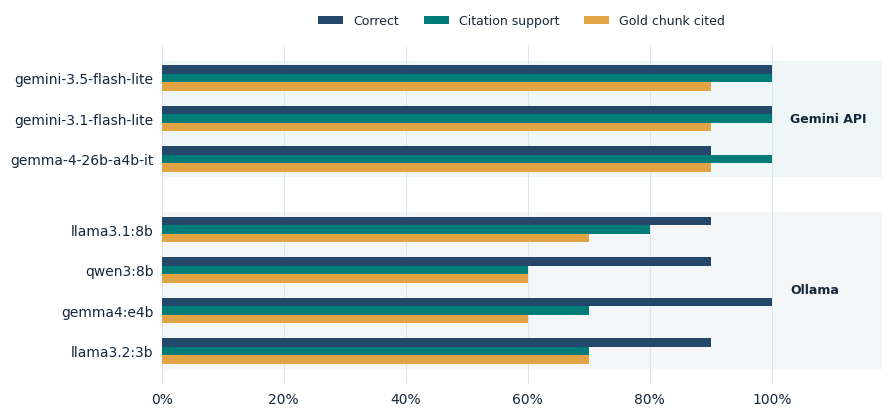

In [7]:
hosted = results["by_provider"]["gemini"]
local = results["by_provider"]["ollama"]
display(Markdown(
    f"Hosted models have **{hosted['grades']['Correct']}/{hosted['n']} Correct** and "
    f"**{hosted['cited_supports']['Yes']}/{hosted['n']} with citation support**. "
    f"Local models have **{local['grades']['Correct']}/{local['n']} Correct** and "
    f"**{local['cited_supports']['Yes']}/{local['n']} with citation support**. "
    f"Of the {local['n'] - local['cited_supports']['Yes']} unsupported local runs, "
    f"{local['correct_without_support']} were graded Correct."
))

fig, ax = plt.subplots(figsize=(8.8, 4.05), layout="constrained")
y = np.arange(len(model_names), dtype=float)
y[hosted_count:] += 0.75
width = 0.21
model_scores = [results["models"][name]["overall"] for name in model_names]
series = [
    ("Correct", blue, [m["grades"]["Correct"] / m["n"] for m in model_scores]),
    ("Citation support", teal, [m["cited_supports"]["Yes"] / m["n"] for m in model_scores]),
    ("Gold chunk cited", amber, [m["cites_gold"] / m["n"] for m in model_scores]),
]
for offset, (label, color, values) in enumerate(series, -1):
    ax.barh(y + offset * width, values, height=width, label=label, color=color)

ax.axhspan(y[0] - 0.43, y[hosted_count - 1] + 0.43, color="#eef6f8", zorder=0)
ax.axhspan(y[hosted_count] - 0.43, y[-1] + 0.43, color="#f4f6f8", zorder=0)
for group, from_row, to_row in (("Gemini API", 0, hosted_count - 1), ("Ollama", hosted_count, len(y) - 1)):
    ax.text(1.03, (y[from_row] + y[to_row]) / 2, group, va="center", fontweight="bold", fontsize=9)

ax.set(yticks=y, yticklabels=model_names, xticks=np.linspace(0, 1, 6), xlim=(0, 1.18))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.grid(axis="x", linewidth=0.7)
ax.tick_params(length=0, pad=6)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=9)
show_figure(fig, "model_grounding_comparison.png")

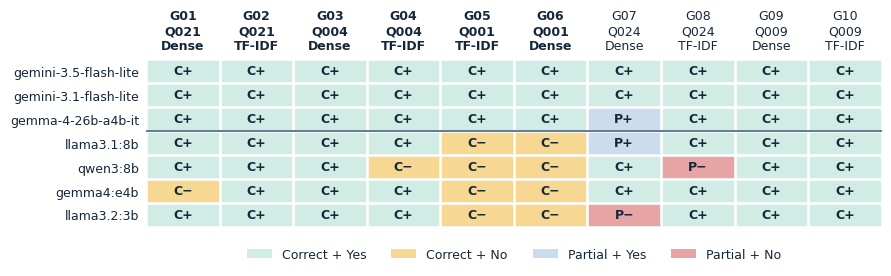

In [8]:
matrix = {
    (row["model"], row["g_id"]): (row["grade"], row["cited_supports"])
    for row in results["answer_grades"]
}
states = [
    (grade, support)
    for grade in evaluate.GRADES for support in evaluate.SUPPORT_VALUES
    if (grade, support) in matrix.values()
]
palette = {
    ("Correct", "Yes"): "#d0ece5", ("Correct", "No"): "#f7d893",
    ("Partial", "Yes"): "#cbdcee", ("Partial", "No"): "#e7a4a5",
}
state_colors = [palette.get(state, "#d8dce3") for state in states]
grade_code = {"Correct": "C", "Partial": "P", "Wrong": "W"}
support_code = {"Yes": "+", "No": "−", "N/A": "·"}
grid = [[states.index(matrix[name, g_id]) for g_id in slots] for name in model_names]

fig, ax = plt.subplots(figsize=(8.8, 2.65), layout="constrained")
ax.imshow(grid, cmap=ListedColormap(state_colors), vmin=-0.5, vmax=len(states) - 0.5, aspect="auto")
for row_index, name in enumerate(model_names):
    for column_index, g_id in enumerate(slots):
        grade, support = matrix[name, g_id]
        ax.text(column_index, row_index, grade_code[grade] + support_code[support],
                ha="center", va="center", fontsize=9, fontweight="bold")
ax.set(
    xticks=list(range(len(slots))),
    xticklabels=[f"{g_id}\n{slot['qa_id']}\n{retriever_labels[slot['retriever']]}" for g_id, slot in slots.items()],
    yticks=list(range(len(model_names))), yticklabels=model_names,
)
ax.xaxis.tick_top()
ax.set_xticks(np.arange(-0.5, len(slots), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(model_names), 1), minor=True)
ax.grid(which="minor", linewidth=1.8, color="white")
ax.axhline(hosted_count - 0.5, color="#607b92", linewidth=1.4)
ax.tick_params(which="both", length=0, pad=5, labelsize=9)
for tick, slot in zip(ax.get_xticklabels(), slots.values()):
    tick.set_fontweight("bold" if slot["highlighted"] else "normal")
ax.legend(
    handles=[Patch(facecolor=color, label=f"{grade} + {support}") for (grade, support), color in zip(states, state_colors)],
    loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=len(states), fontsize=9,
)
show_figure(fig, "question_model_matrix.png")

## 5. Failure analyses

The 70 paired answers at K = 3 received 66 Correct, 4 Partial and 0 Wrong grades. The two analyses use the observed retrieval omissions, graded partial answers and unsupported citations. They also include a development abstention that qualifies as Wrong under the rubric and sits outside the blind comparison.

### 5.1. Q024 and Q019 — Evidence rank and boundary sensitivity

Dense placed `chk_D024_000_76a1bcf7` fourth for Q024. The top three were all from D024. The gold chunk opens with tutorial metadata and an introduction about the previous tutorial, a plausible contributor to its lower rank. The logs establish the rank and its effect on the context. They leave the cause of the scoring difference open.

Three dense answers were Partial. Two restricted Automapping to collision areas or omitted automatic layer and tile filling. The `llama3.2:3b` answer also claimed “reduzindo a complexidade do processo”, which the cited passage did not support. Four models still gave Correct answers with supporting citations because other chunks describe the TMX rules and demonstrate automatic layer filling.

In [9]:
def quote(label, text):
    display(Markdown(f"**{label}**\n\n> " + text.replace("\n", "\n> ")))


def detail_table(rows):
    return pd.DataFrame([
        {
            "Model": r["model"],
            "Slot": r["g_id"],
            "Grade": r["grade"],
            "Support": r["cited_supports"],
            "Gold in context": r["gold_in_context"],
            "Gold cited": r["cites_gold"],
            "Cited numbers": r["cited_numbers"],
            "Invalid numbers": r["invalid_cited_numbers"],
        }
        for r in rows
    ]).set_index("Model")


def passage_between(chunk_id, start, end):
    passage = chunks[chunk_id]["text"]
    left = passage.index(start)
    right = passage.index(end, left) + len(end)
    return passage[left:right]


q024 = questions["Q024"]
quote("Q024 question", q024["question"])
quote("Annotated span in " + q024["gold_chunk_ids"][0], q024["evidence_span"])
for chunk_id in slots["G07"]["retrieved_chunk_ids"]:
    print(chunk_id)
quote("Retrieved restatement about rule files", passage_between(
    "chk_D024_002_4cb5683f", "O Automapping é uma ferramenta", "outros arquivos TMX."
))
quote("Retrieved example of automatic layer filling", passage_between(
    "chk_D024_003_0dc95624", "Note que o Tiled criou", "na camada “Colisao”."
))

q024_dense = [row for row in results["non_perfect"] if row["g_id"] == "G07"]
display(detail_table(q024_dense))
for row in q024_dense:
    if row["grade"] == "Partial" or row["model"] == primary:
        quote(f"{row['model']} answer", row["answer"])
        quote("Grader's note", row["notes"])

**Q024 question**

> O que é a ferramenta Automapping no Tiled?

**Annotated span in chk_D024_000_76a1bcf7**

> A principal ideia dela é preencher camadas com tiles específicos, conforme regras descritas em outros arquivos TMX.

chk_D024_003_0dc95624
chk_D024_002_4cb5683f
chk_D024_001_913d73a2


**Retrieved restatement about rule files**

> O Automapping é uma ferramenta que se baseia em regras definidas em outros arquivos TMX.

**Retrieved example of automatic layer filling**

> Note que o Tiled criou uma camada chamada “Colisao” e adicionou automaticamente onde tinha pedra um tile vermelho na camada “Colisao”.

,Slot,Grade,Support,Gold in context,Gold cited,Cited numbers,Invalid numbers
Model,,,,,,,
gemini-3.5-flash-lite,G07,Correct,Yes,False,False,"[1, 2, 3]",[]
gemini-3.1-flash-lite,G07,Correct,Yes,False,False,"[1, 2, 3]",[]
gemma-4-26b-a4b-it,G07,Partial,Yes,False,False,"[1, 2, 3]",[]
llama3.1:8b,G07,Partial,Yes,False,False,"[1, 2]",[]
qwen3:8b,G07,Correct,Yes,False,False,"[2, 3]",[]
gemma4:e4b,G07,Correct,Yes,False,False,"[1, 2, 3]",[]
llama3.2:3b,G07,Partial,No,False,False,[2],[]


... (4 outputs left out)

**llama3.1:8b answer**

> A ferramenta Automapping no Tiled é uma ferramenta que se baseia em regras definidas em outros arquivos TMX e permite automatizar o preenchimento de áreas de colisão em mapas.

**Grader's note**

> Indica regras em outros arquivos TMX e preenchimento automático, mas restringe a definição a áreas de colisão sem mencionar camadas/tiles ou que é apenas um exemplo.

**llama3.2:3b answer**

> A ferramenta Automapping no Tiled é uma ferramenta que se baseia em regras definidas em outros arquivos TMX. Ela permite automatizar a preenchimento de áreas de colisão em mapas, economizando tempo e reduzindo a complexidade do processo.

**Grader's note**

> Restringe o preenchimento automático a áreas de colisão sem indicar camadas/tiles em geral, e o único trecho citado (chk_D024_002_4cb5683f) não menciona economia de tempo nem redução de complexidade.

In [10]:
q019 = questions["Q019"]
quote("Q019 development question", q019["question"])
quote("Reference answer", q019["gold_answer"])
for row in results["development_probe"]:
    name = row["retriever"]
    rank = retrieval["retrievers"][name]["first_gold_rank"][row["qa_id"]]
    verdict = "Wrong by the abstention rubric" if row["rubric_grade"] == "Wrong" else "Answer matches the reference on inspection"
    display(Markdown(
        f"**{retriever_labels[name]} · K = {row['k']}** — "
        f"gold at rank {rank}, shown chunk `{row['retrieved_chunk_ids'][0]}`. {verdict}."
    ))
    quote("Logged answer", row["answer"])

**Q019 development question**

> O que os triângulos superiores no Histograma indicam?

**Reference answer**

> Os triângulos superiores no Histograma indicam recortes de sombra e realces, onde o triângulo da esquerda indica corte de preto e o da direita indica realces exagerados.

**TF-IDF · K = 1** — gold at rank 3, shown chunk `chk_D019_000_7645ac03`. Wrong by the abstention rubric.

**Logged answer**

> O contexto fornecido não contém informações sobre o que os triângulos superiores no Histograma indicam, portanto não é possível responder.

**Dense · K = 1** — gold at rank 1, shown chunk `chk_D019_002_76fa3d81`. Answer matches the reference on inspection.

**Logged answer**

> Os dois pequenos triângulos na parte superior esquerda e à direita do histograma indicam os Alertas de Clipping (recortes de sombra e realces). O triângulo da esquerda indica um corte de preto (área da imagem em preto puro sem outras informações) e o da direita indica realces exagerados (área da imagem branca sem outras informações).

TF-IDF returned a Lightroom introduction that repeats “Histograma”. The model abstained because K = 1 excluded the gold chunk. Dense ranked the gold chunk first and the answer identified shadow clipping and blown highlights. This pair demonstrates sensitivity to the context cutoff. Q024 also shows the limit of one annotated span when other chunks contain supporting evidence.

### 5.2. Q001 and Q024 — Unsupported citations with evidence in context

Both Q001 prompts put the COBIT definition at passage [1]. Slide numbers appear immediately before and after the definition. All eight local answers included citation [3], a pattern consistent with copying the slide number into the citation field. Three answers also emitted an out-of-range [4] or [17]. Each answer was Correct and had citation support graded No. The hosted models cited [1] with supporting evidence in all six answers.

In [11]:
q001 = questions["Q001"]
quote("Q001 question", q001["question"])
quote("Slide text in prompt passage [1]", passage_between(
    q001["gold_chunk_ids"][0], "José Oliveira 2 3 Modelo orientado", "4 COBIT Versão 4.1"
))
q001_local = [r for r in results["non_perfect"] if r["qa_id"] == "Q001"]
display(detail_table(q001_local))
for name, g_id in (("gemma4:e4b", "G05"), ("llama3.2:3b", "G06")):
    row = next(r for r in q001_local if r["model"] == name and r["g_id"] == g_id)
    quote(f"{name} {g_id} answer", row["answer"])
    quote("Grader's note", row["notes"])

**Q001 question**

> O que é o framework COBIT e quais são os principais standards de TI que ele integra?

**Slide text in prompt passage [1]**

> José Oliveira 2 3 Modelo orientado para a governação das tecnologias de informação Framework internacional unificadora que integra os principais standards de TI, incluindo ITIL, CMMI e ISO José Oliveira 3 4 COBIT Versão 4.1

,Slot,Grade,Support,Gold in context,Gold cited,Cited numbers,Invalid numbers
Model,,,,,,,
llama3.1:8b,G05,Correct,No,True,False,"[3, 3]",[]
llama3.1:8b,G06,Correct,No,True,False,"[3, 4]",[4]
qwen3:8b,G05,Correct,No,True,False,[3],[]
qwen3:8b,G06,Correct,No,True,False,"[3, 2]",[]
gemma4:e4b,G05,Correct,No,True,False,[3],[]
gemma4:e4b,G06,Correct,No,True,False,[3],[]
llama3.2:3b,G05,Correct,No,True,False,"[3, 4]",[4]
llama3.2:3b,G06,Correct,No,True,False,"[3, 17]",[17]


**gemma4:e4b G05 answer**

> O COBIT é um framework internacional unificadora que integra os principais standards de TI, incluindo ITIL, CMMI e ISO.

**Grader's note**

> O trecho citado chk_D001_003_034d787c não define o COBIT como framework internacional unificador nem menciona ITIL ou ISO.

**llama3.2:3b G06 answer**

> O COBIT é um framework internacional unificadora que integra os principais standards de TI, incluindo ITIL, CMMI e ISO.

**Grader's note**

> O trecho citado chk_D001_001_05b0f5f9 não define o COBIT como framework internacional unificador nem menciona ITIL ou ISO.

On TF-IDF Q024, qwen3 cited the gold chunk and still scored Partial with unsupported citations. It attached “fronteiras de rios e barro” to Automapping. The same passage attributes that phrase to terrain editing in the previous tutorial. Correct retrieval and a gold citation still leave the generator responsible for linking claims to the right evidence.

In [12]:
row = next(r for r in results["non_perfect"] if r["g_id"] == "G08" and r["model"] == "qwen3:8b")
display(detail_table([row]))
quote("Gold chunk excerpt about the previous tutorial", passage_between(
    q024["gold_chunk_ids"][0], "No último tutorial", "fronteiras de rios e barro, por exemplo."
))
quote("qwen3:8b answer", row["answer"])
quote("Grader's note", row["notes"])

other_cases = [
    row for row in results["non_perfect"]
    if (row["model"], row["g_id"]) in {("gemma4:e4b", "G01"), ("qwen3:8b", "G04")}
]
display(detail_table(other_cases))
for row in other_cases:
    quote(f"{row['model']} {row['g_id']} grader's note", row["notes"])

,Slot,Grade,Support,Gold in context,Gold cited,Cited numbers,Invalid numbers
Model,,,,,,,
qwen3:8b,G08,Partial,No,True,True,"[1, 2, 3]",[]


**Gold chunk excerpt about the previous tutorial**

> No último tutorial eu mostrei como utilizar de forma inteligente a ferramenta de edição de terrenos. Vimos como o Tiled realiza o preenchimento automático de fronteiras de rios e barro, por exemplo.

**qwen3:8b answer**

> A ferramenta Automapping no Tiled é uma funcionalidade que permite preencher camadas com tiles específicos, conforme regras definidas em outros arquivos TMX. Ela ajuda a economizar tempo ao automatizar tarefas como a criação de áreas de colisão, fronteiras de rios e barro, entre outros. Com o Automapping, o usuário define regras e o próprio Tiled preenche conforme deseja.

**Grader's note**

> Atribui incorretamente ao Automapping fronteiras de rios e barro, que em chk_D024_000_76a1bcf7 referem-se à ferramenta de edição de terrenos do tutorial anterior.

,Slot,Grade,Support,Gold in context,Gold cited,Cited numbers,Invalid numbers
Model,,,,,,,
qwen3:8b,G04,Correct,No,True,False,[2],[]
gemma4:e4b,G01,Correct,No,True,False,[2],[]


**qwen3:8b G04 grader's note**

> O único trecho citado trata de versão paga, download e ActiveX, sem mencionar Criar Página Web, Catwebpage.html ou fotos na página.

**gemma4:e4b G01 grader's note**

> O único trecho citado (chk_D021_000_3fe2a25c) corta em "CausaEste problema ocorre porque a" e não contém a causa.

### Exception index and operational retries

The index includes every final record with a grade below Correct, citation support below Yes, absent annotated evidence or inconsistent citation output. Historical failed attempts are listed separately from graded final answers.

In [13]:
display(detail_table(results["non_perfect"]).reset_index().sort_values(["Slot", "Model"]).reset_index(drop=True))

failed_attempts = [
    {
        "Model": name,
        "Question": row["qa_id"],
        "Retriever": retriever_labels[row["retriever"]],
        "Logged error": row["error"].partition(".")[0],
        "Recovered": row["recovered"],
    }
    for name, info in results["models"].items() for row in info["failed_attempts"]
]
display(pd.DataFrame(failed_attempts))

,Model,Slot,Grade,Support,Gold in context,Gold cited,Cited numbers,Invalid numbers
0,gemma4:e4b,G01,Correct,No,True,False,[2],[]
1,qwen3:8b,G04,Correct,No,True,False,[2],[]
2,gemma4:e4b,G05,Correct,No,True,False,[3],[]
3,llama3.1:8b,G05,Correct,No,True,False,"[3, 3]",[]
4,llama3.2:3b,G05,Correct,No,True,False,"[3, 4]",[4]
5,qwen3:8b,G05,Correct,No,True,False,[3],[]
6,gemma4:e4b,G06,Correct,No,True,False,[3],[]
7,llama3.1:8b,G06,Correct,No,True,False,"[3, 4]",[4]
8,llama3.2:3b,G06,Correct,No,True,False,"[3, 17]",[17]
9,qwen3:8b,G06,Correct,No,True,False,"[3, 2]",[]


,Model,Question,Retriever,Logged error,Recovered
0,gemini-3.5-flash-lite,Q024,TF-IDF,ServerError: 503 UNAVAILABLE,True
1,gemma-4-26b-a4b-it,Q004,Dense,ServerError: 503 UNAVAILABLE,True


## 6. Search risk and mitigation

The dominant risk is intra-document competition. Generic introductions, navigation text and section fragments can outrank evidence from the same document. Across both retrievers, 17 of 18 top-1 evidence misses already had the target document at rank 1. RRF retained 64% chunk recall@1 and 0.803 MRR, so combining these ranks did little for the shared errors.

Q005 shows a related lexical failure across documents. The question is underspecified and the QGIS download passage overlaps on phrasing. The intended passage uses “datasets” where the question uses “dados”.

In [14]:
miss = methods["TF-IDF"]["wrong_doc_at_1"][0]
q005 = questions[miss["qa_id"]]
quote("Q005 question", q005["question"])
quote("Rank 1, " + miss["ranked_chunk_id"], passage_between(
    miss["ranked_chunk_id"], "módulos adicionais do formato GDAL", "disponíveis em kyngchaos.com."
))
quote(f"Annotated evidence in {q005['doc_id']} at rank {miss['first_gold_rank']}", q005["evidence_span"])

**Q005 question**

> Em que formatos os dados estão disponíveis?

**Rank 1, chk_D011_001_a3d053f3**

> módulos adicionais do formato GDAL e grelhas PROJ estão disponíveis em kyngchaos.com.

**Annotated evidence in D005 at rank 2**

> Os datasets que disponibilizamos são publicados em CSV e JSON

**Proposed mitigation.** Remove extraction boilerplate such as navigation and slide numbers, then chunk at section or paragraph boundaries and carry the section title with each passage. Retrieve a wider hybrid candidate pool at K = 5, where both saved retrievers covered all 25 annotated spans, and use a cross-encoder to rerank the strongest three passages. Pair this with [C1]–[C3] labels, post-generation citation checks and explicit abstention. The proposal would need validation on a fresh question set.

## 7. Interpretation and reproducibility

- Retrieval uses 25 questions. Model comparisons share the same five paired questions, so the 70 graded answers are repeated responses on this small sample. The study supports qualitative comparisons.
- Prompt development used only the default model and non-paired questions. The author had already inspected ranks while sizing K. Hosted output can vary even at temperature 0 with a fixed seed.
- The source hashes in the archived records identify the M3 revisions used for generation. The saved paired jobs and settings agree with the frozen evaluation inputs. Differences in inference stack and prompt fit may contribute to the provider-level gap.
- Gold denotes the annotated span. The Q024 citations show that a different passage can support a correct answer. Q019 development answers are outside the manually graded sample.
- Latencies are observed call times, excluding inter-call pauses. The CPU-only Ollama timings reflect the laptop used for the runs. Counts use each serving stack's tokenizer. A dash in the token table indicates a total the provider did not report.

Run `python src/evaluate.py` to write the detailed summary at `runs/m4_evaluation_summary.json`. The summary includes per-model retriever and highlighted slices, latency and usage, and verbatim notes for the exceptions. Run `python -m pytest` for the checks. The short report is in `report/report.pdf`.